# Debug CUDA-MPI Q3D code

## Initialization

If `visxd` or `zdf` modules are missing (or in need of an update), run the following command to install them in the local environment:

In [ ]:
! pip3 install -q -e ../zdf/python && pip3 install -q --no-deps -e ../visxd && echo "zdf and visxd modules installed ok"

### cyl3_cylgrid

Tests `cyl_modes::tiled<float>` creation.

Plotting test/cylgrid1_z.zdf


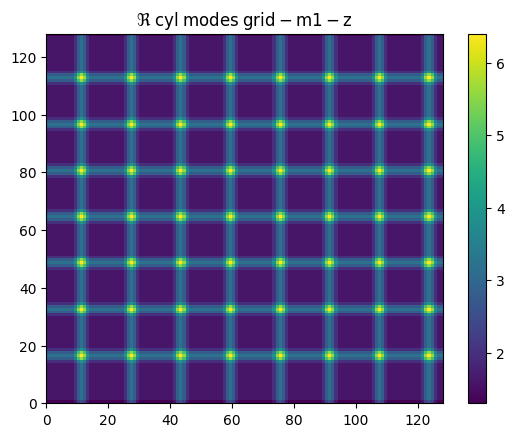

Plotting test/cylgrid1_r.zdf


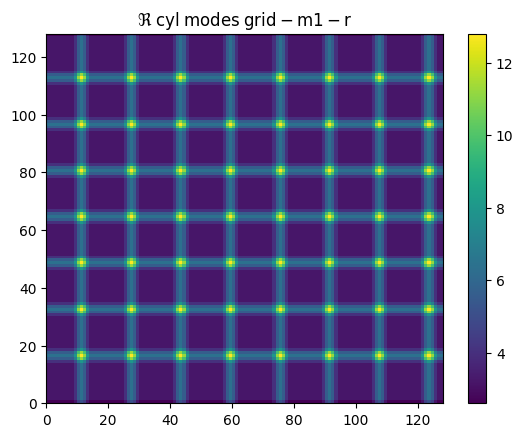

Plotting test/cylgrid1_th.zdf


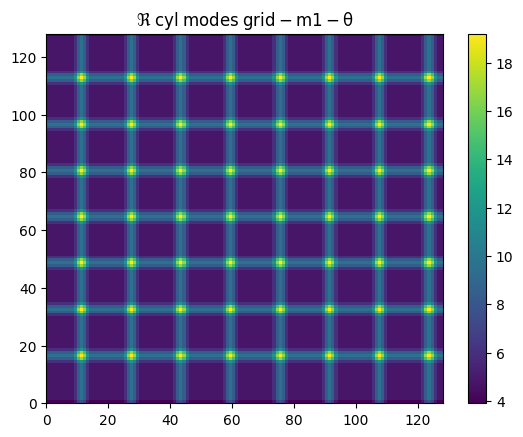

In [ ]:
import visxd.cyl as vis

# visxd.grid2d("test/cylgrid0_z.zdf" )
# visxd.grid2d("test/cylgrid0_r.zdf" )
# visxd.grid2d("test/cylgrid0_th.zdf" )

vis.plot_data("test/cylgrid1_z.zdf", part = 'real' )
vis.plot_data("test/cylgrid1_r.zdf", part = 'real' )
vis.plot_data("test/cylgrid1_th.zdf", part = 'real' )

### Laser test

`test_laser()`


In [10]:
! make -j 12 && mpirun -np 4 ./zpic

[c++]  laser.cpp
[link]  zpic
Environment
MPI running on 4 processes
GPU devices on rank 0 (GPUA100):
Device Number           : 0 (of 1)
  Device name           : NVIDIA A100 80GB PCIe
  Max. block size       : 1024
  Warp size             : 32
  Max. warps/block      : 32
  Shared memory (def.)  : 48 (kB) 
  Shared memory (optin) : 163 (kB) 
Running test_laser()...
Using dt = 0.0175145
(*info*) Created (2, 2) Partition object
Completed test_laser()



#### Electric field

Plotting EMF/E1z-001000.zdf


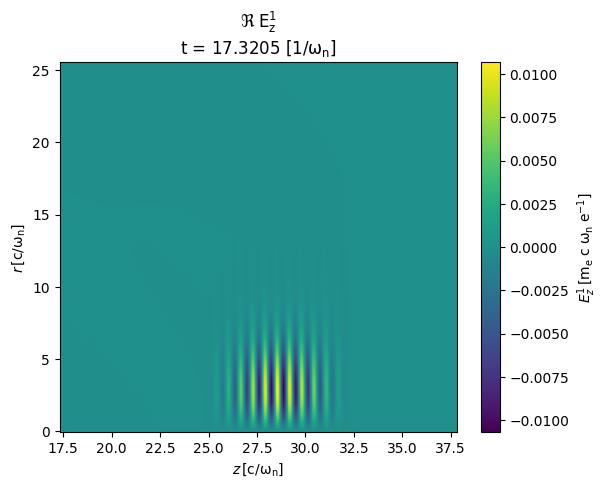

Plotting EMF/E1z-001000.zdf


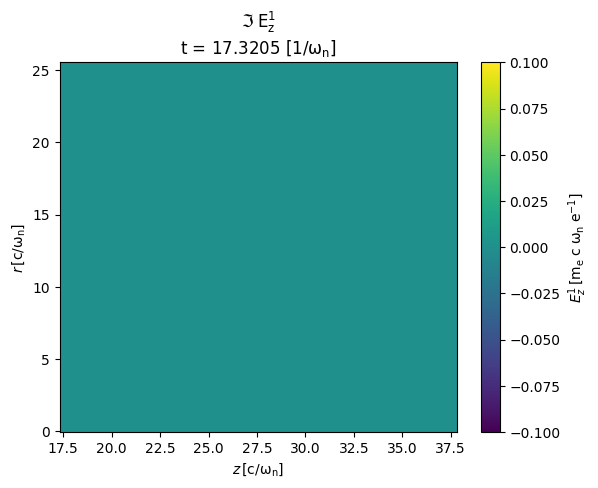

Plotting EMF/E1r-001000.zdf


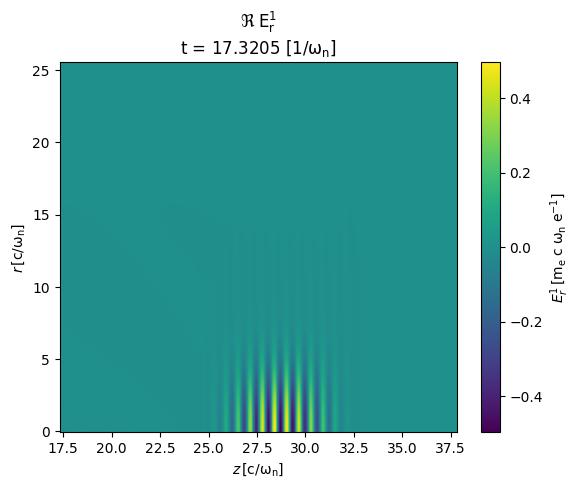

Plotting EMF/E1r-001000.zdf


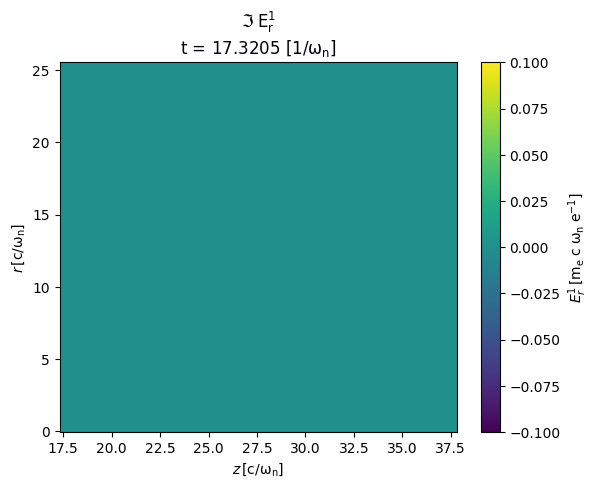

Plotting EMF/E1θ-001000.zdf


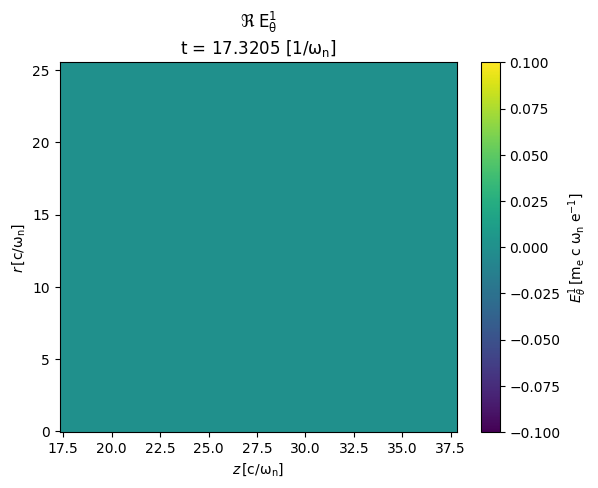

Plotting EMF/E1θ-001000.zdf


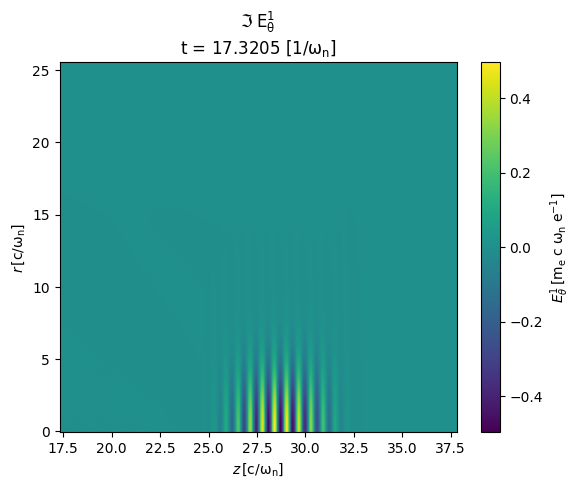

In [ ]:
import visxd.cyl as vis
import matplotlib.colors as colors

def fname( comp, iter ):
    return "EMF/{:s}-{:06d}.zdf".format( comp, iter )

# ! ls EMF/*.zdf

# iter = 0
iter = 1000

vis.plot_data(fname("E1z", iter), part = 'real', vsim = True )
vis.plot_data(fname("E1z", iter), part = 'imag', vsim = True )
vis.plot_data(fname("E1r", iter), part = 'real', vsim = True )
vis.plot_data(fname("E1r", iter), part = 'imag', vsim = True )
vis.plot_data(fname("E1θ", iter), part = 'real', vsim = True )
vis.plot_data(fname("E1θ", iter), part = 'imag', vsim = True )

#### Magnetic field

Plotting EMF/B1z-001000.zdf


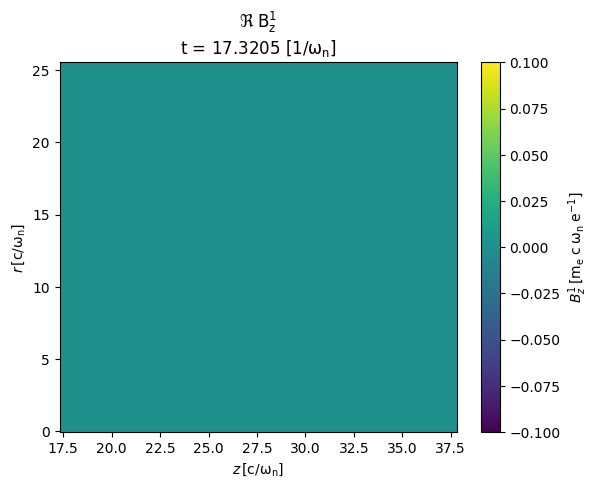

Plotting EMF/B1z-001000.zdf


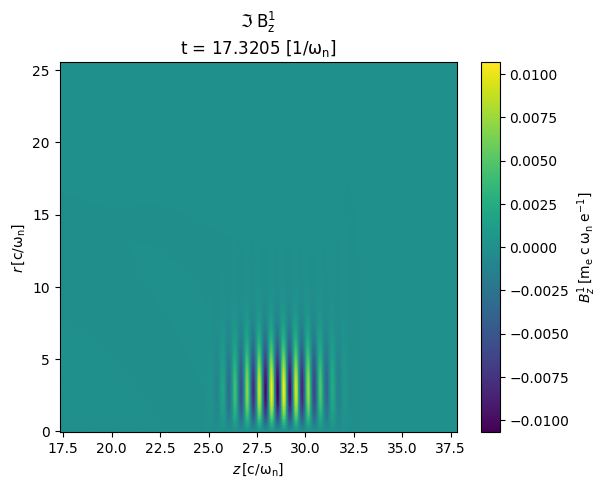

Plotting EMF/B1r-001000.zdf


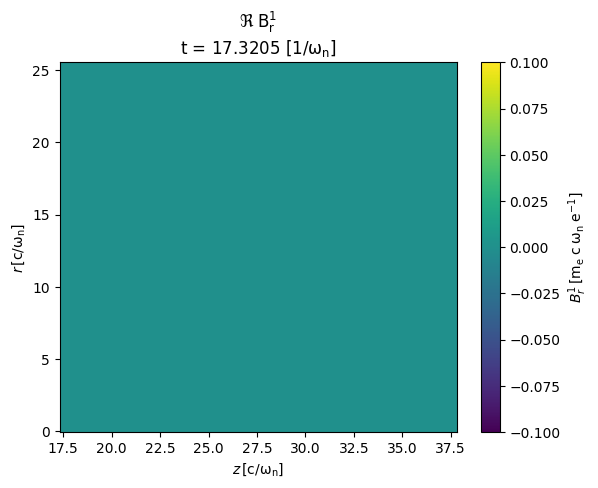

Plotting EMF/B1r-001000.zdf


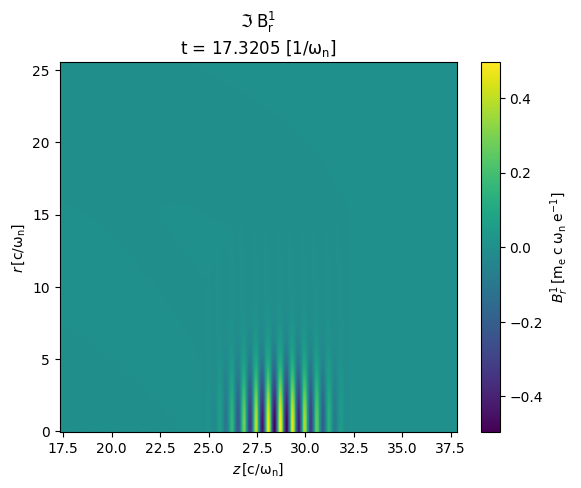

Plotting EMF/B1θ-001000.zdf


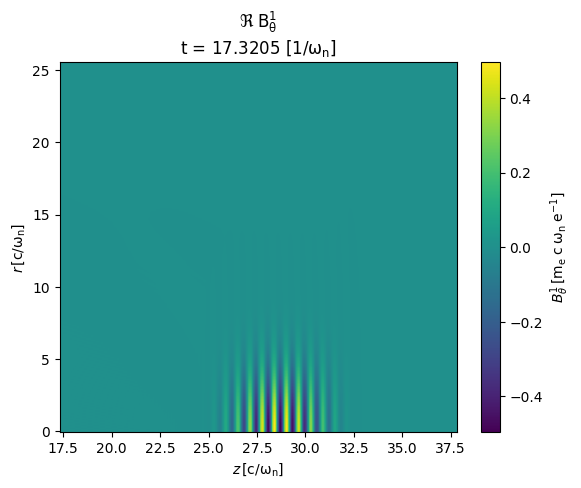

Plotting EMF/B1θ-001000.zdf


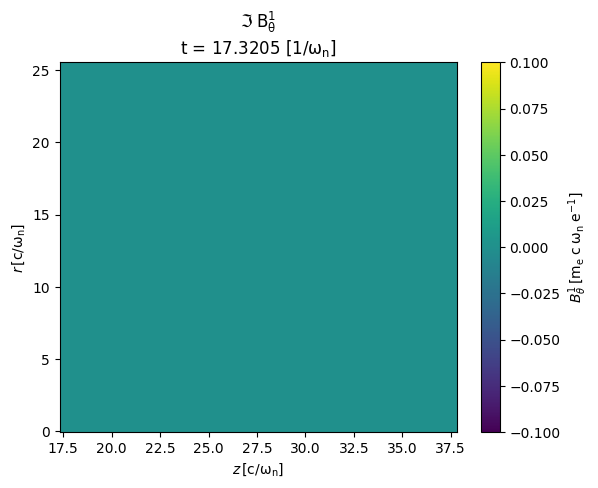

In [ ]:
import visxd.cyl as vis
import matplotlib.colors as colors

def fname( comp, iter ):
    return "EMF/{:s}-{:06d}.zdf".format( comp, iter )

# ! ls EMF/*.zdf

# iter = 0
iter = 1000

vis.plot_data(fname("B1z", iter), part = 'real', vsim = True )
vis.plot_data(fname("B1z", iter), part = 'imag', vsim = True )
vis.plot_data(fname("B1r", iter), part = 'real', vsim = True )
vis.plot_data(fname("B1r", iter), part = 'imag', vsim = True )
vis.plot_data(fname("B1θ", iter), part = 'real', vsim = True )
vis.plot_data(fname("B1θ", iter), part = 'imag', vsim = True )

### Particle Injection test


In [8]:
! make -j 12 && mpirun -np 4 ./zpic

make: Nothing to be done for 'all'.
Environment
MPI running on 4 processes
GPU devices on rank 0 (GPUA100):
Device Number           : 0 (of 1)
  Device name           : NVIDIA A100 80GB PCIe
  Max. block size       : 1024
  Warp size             : 32
  Max. warps/block      : 32
  Shared memory (def.)  : 48 (kB) 
  Shared memory (optin) : 163 (kB) 
Running test_inj()...
Completed test_inj()


Plotting PARTICLES/electrons/particles-electrons-000000.zdf


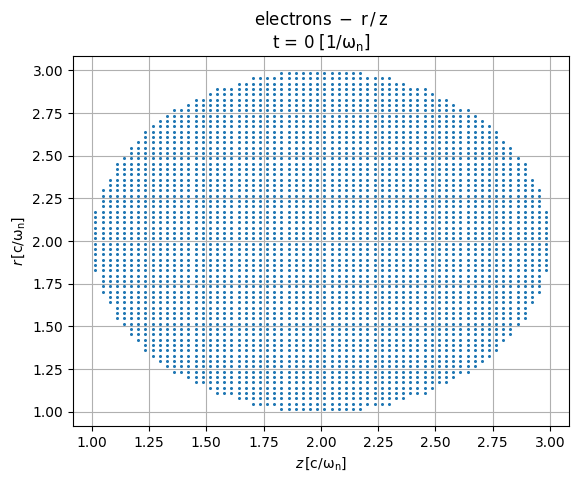

Plotting PARTICLES/electrons/particles-electrons-000000.zdf


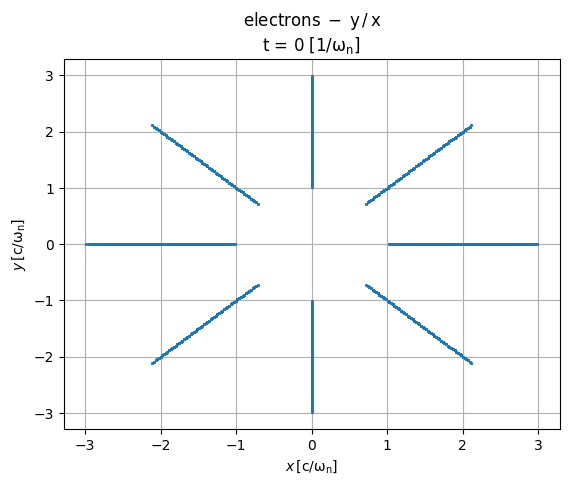

Plotting CHARGE/electrons/electrons-ρ0-000000.zdf


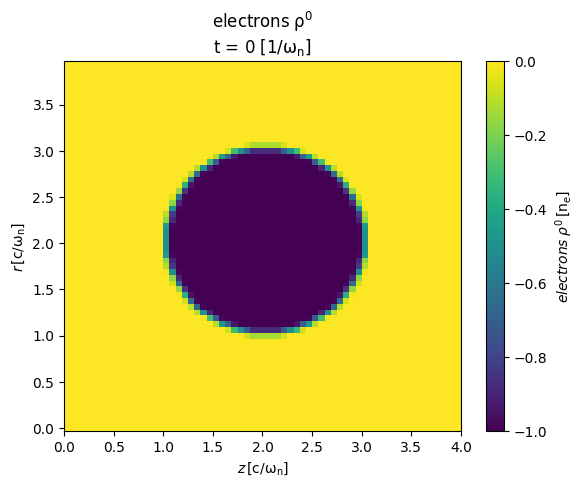

In [4]:
import visxd.cyl as vis

vis.plot_data("PARTICLES/electrons/particles-electrons", 0 )
vis.plot_data("PARTICLES/electrons/particles-electrons", 0, qx = 'x', qy = 'y' )
vis.plot_data("CHARGE/electrons/electrons-ρ0", 0)

### Particle motion test

In [23]:
! make -j 12 && mpirun -np 4 ./zpic

make: Nothing to be done for 'all'.
Environment
MPI running on 4 processes
GPU devices on rank 0 (GPUA100):
Device Number           : 0 (of 1)
  Device name           : NVIDIA A100 80GB PCIe
  Max. block size       : 1024
  Warp size             : 32
  Max. warps/block      : 32
  Shared memory (def.)  : 48 (kB) 
  Shared memory (optin) : 163 (kB) 
Running test_mov()...
Completed test_mov()


Plotting CHARGE/electrons/electrons-ρ0-000000.zdf


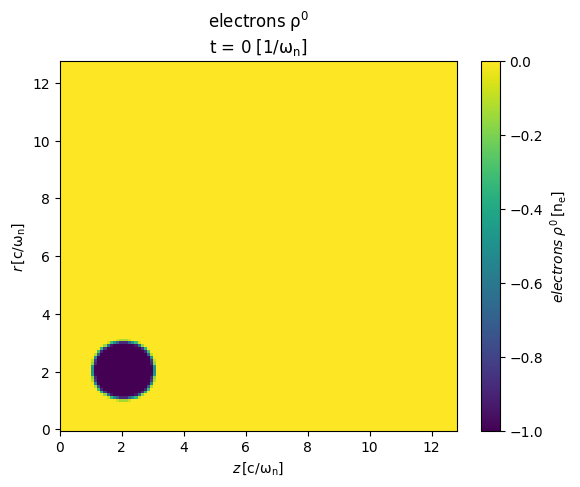

Plotting CHARGE/electrons/electrons-ρ0-000100.zdf


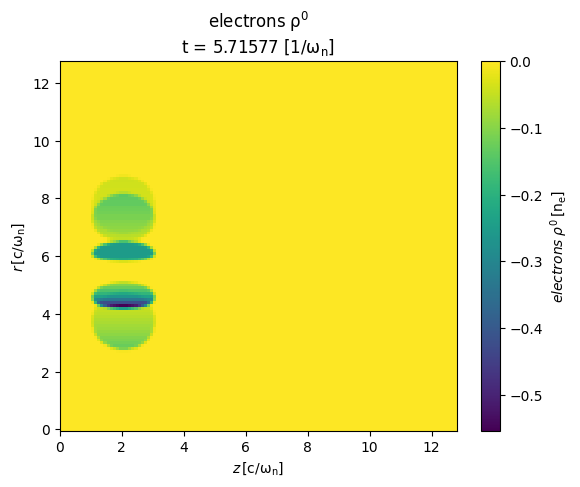

Plotting PARTICLES/electrons/particles-electrons-000100.zdf


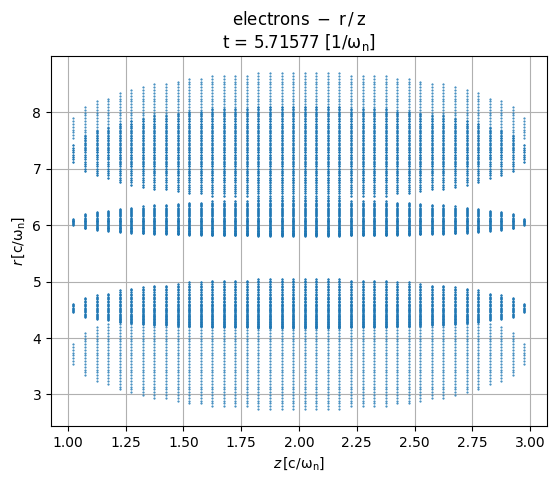

In [ ]:
import visxd.cyl as vis

iter = 100

vis.plot_data("CHARGE/electrons/electrons-ρ0", 0)
vis.plot_data("CHARGE/electrons/electrons-ρ0", iter)
vis.plot_data("PARTICLES/electrons/particles-electrons", iter, qx = 'z', qy = 'r' )

### Current deposit test

**Note**: The imaginary part of current and fields (for any m > 0) will have the opposite sign from the OSIRIS implementation.

In [70]:
! make -j 12 && mpirun -np 4 ./zpic

[c++]  current.cpp
[link] zpic
quasi-3D tests
SIMD support not enabled
OpenMP enabled
  # procs           : 14
  max_threads       : 14
  default # threads : 14
Running test_current()...
Completed test_current()


#### Current and charge, m = 0

Plotting CHARGE/electrons/electrons-ρ0-000001.zdf


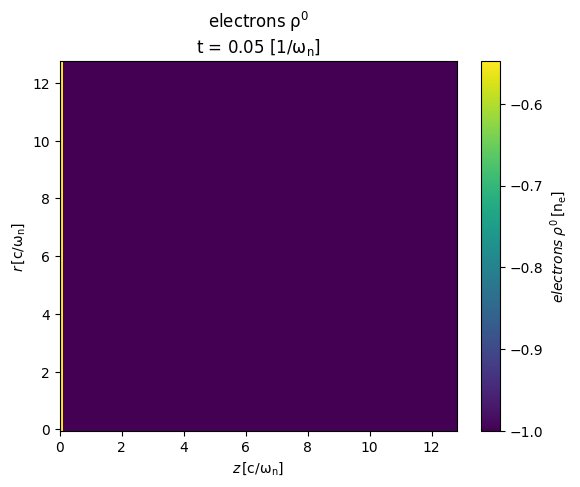

Plotting CURRENT/J0z-000001.zdf


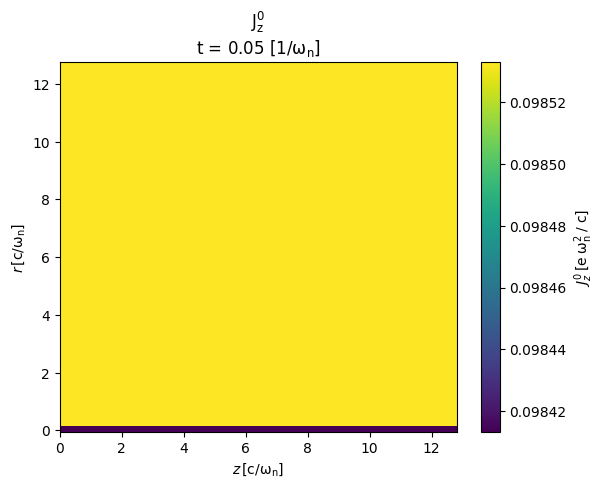

Plotting CURRENT/J0r-000001.zdf


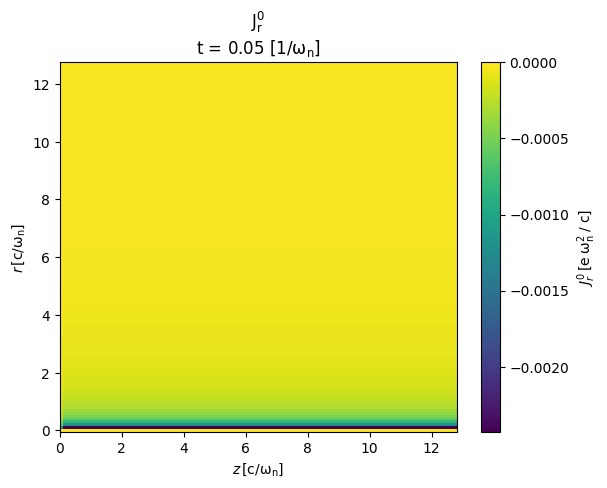

Plotting CURRENT/J0θ-000001.zdf


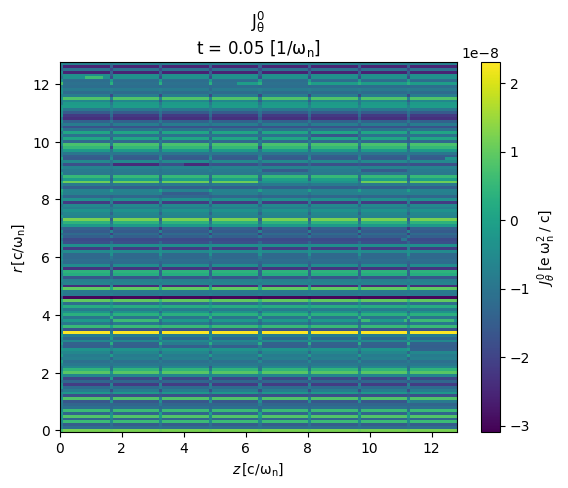

In [ ]:
import visxd.cyl as vis

iter = 1

vis.plot_data("CHARGE/electrons/electrons-ρ0", iter)

vis.plot_data("CURRENT/J0z", iter)
vis.plot_data("CURRENT/J0r", iter)
vis.plot_data("CURRENT/J0θ", iter)

#### Current m = 1

Plotting CURRENT/J1z-000001.zdf


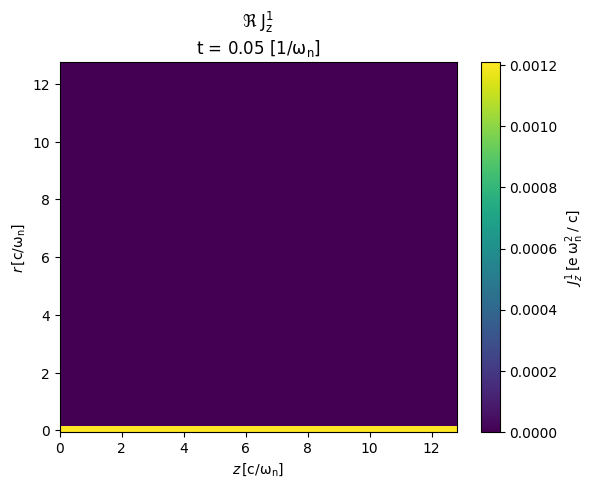

Plotting CURRENT/J1z-000001.zdf


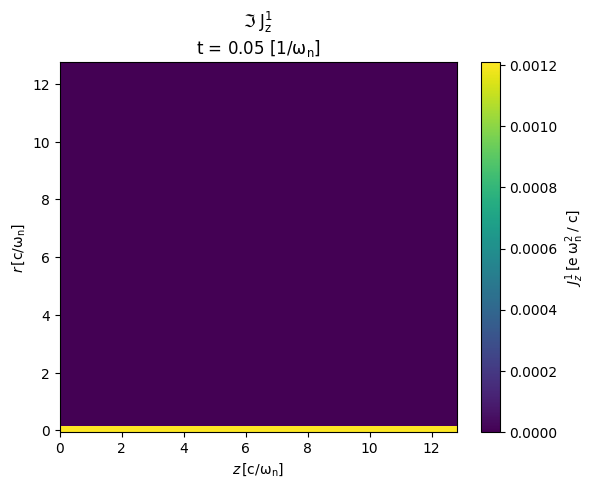

Plotting CURRENT/J1r-000001.zdf


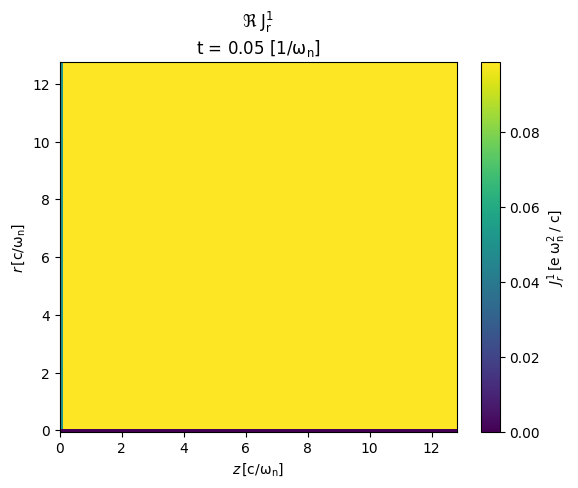

Plotting CURRENT/J1r-000001.zdf


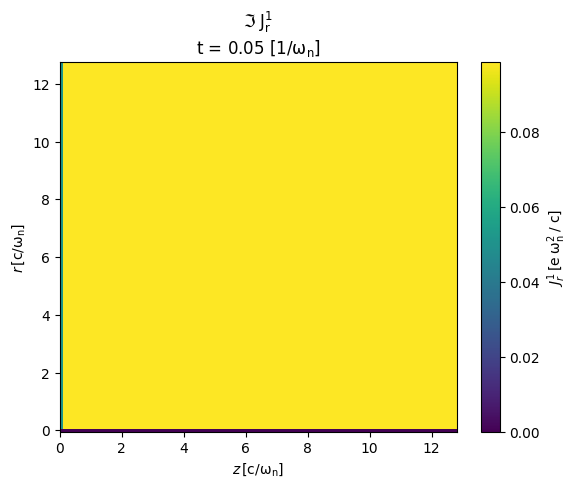

Plotting CURRENT/J1θ-000001.zdf


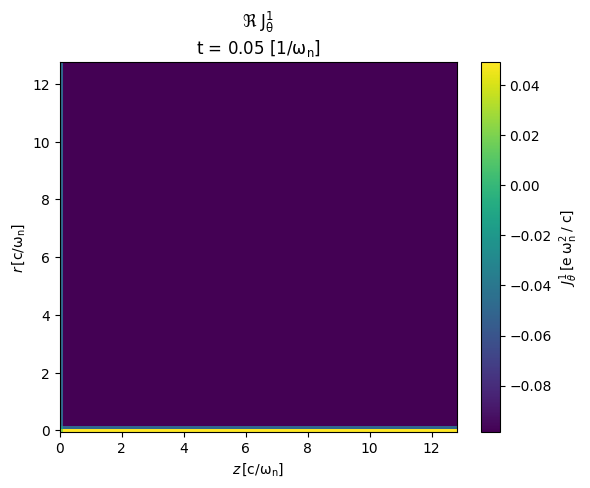

Plotting CURRENT/J1θ-000001.zdf


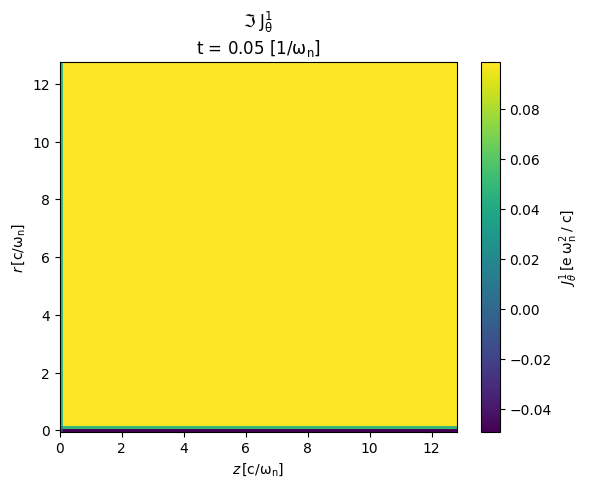

In [ ]:
import visxd.cyl as vis

def fname( comp, iter ):
    return "CURRENT/{:s}-{:06d}.zdf".format( comp, iter )

iter = 1

# vis.plot_data("CHARGE/electrons/electrons-ρ1", iter)

vis.plot_data(fname("J1z", iter), part = 'real' )
vis.plot_data(fname("J1z", iter), part = 'imag' )
vis.plot_data(fname("J1r", iter), part = 'real' )
vis.plot_data(fname("J1r", iter), part = 'imag' )
vis.plot_data(fname("J1θ", iter), part = 'real' )
vis.plot_data(fname("J1θ", iter), part = 'imag' )

#### Electric field

Mode m = 1

Plotting EMF/E1z-000050.zdf


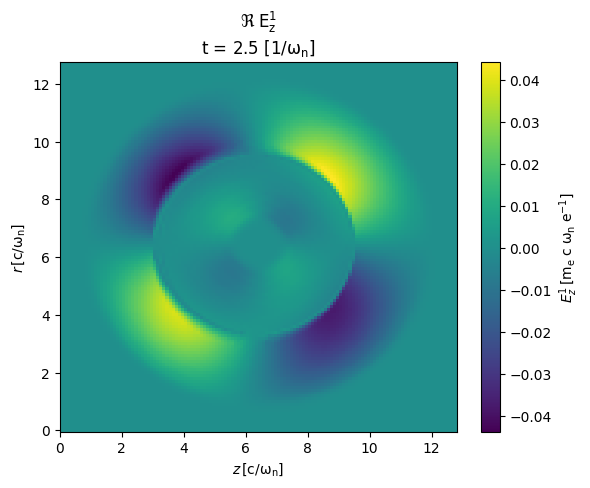

Plotting EMF/E1z-000050.zdf


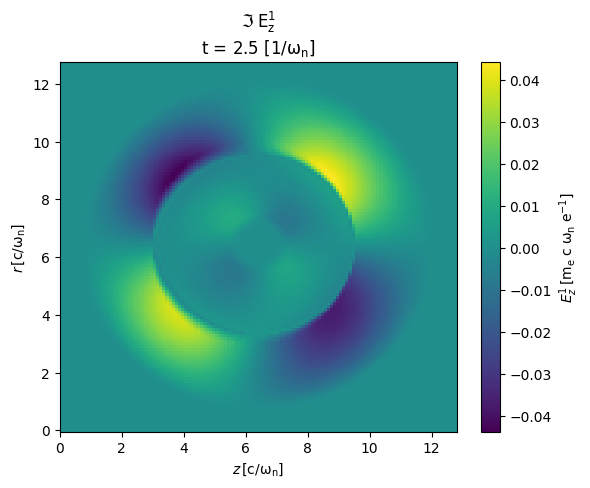

Plotting EMF/E1r-000050.zdf


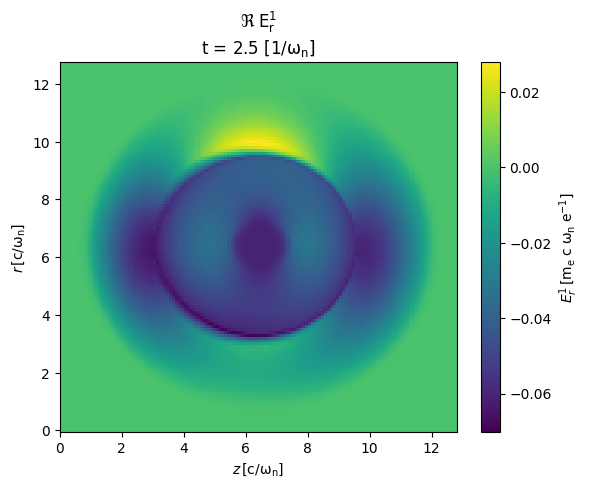

Plotting EMF/E1r-000050.zdf


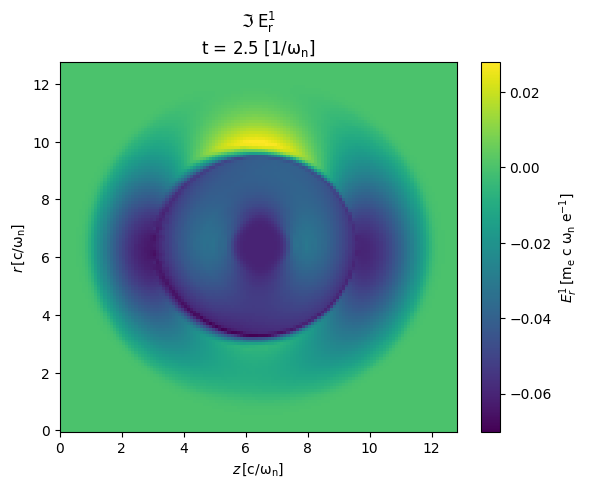

Plotting EMF/E1θ-000050.zdf


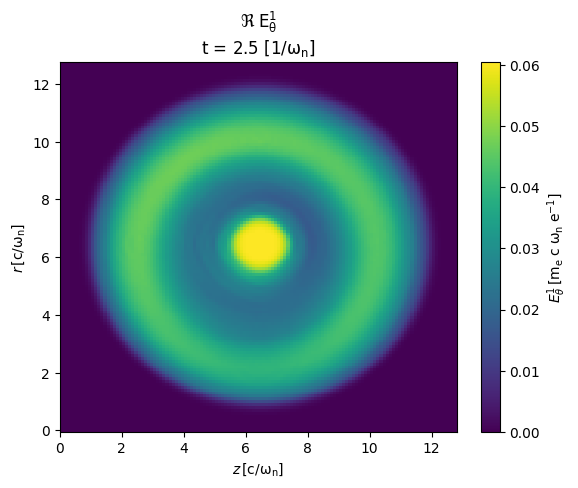

Plotting EMF/E1θ-000050.zdf


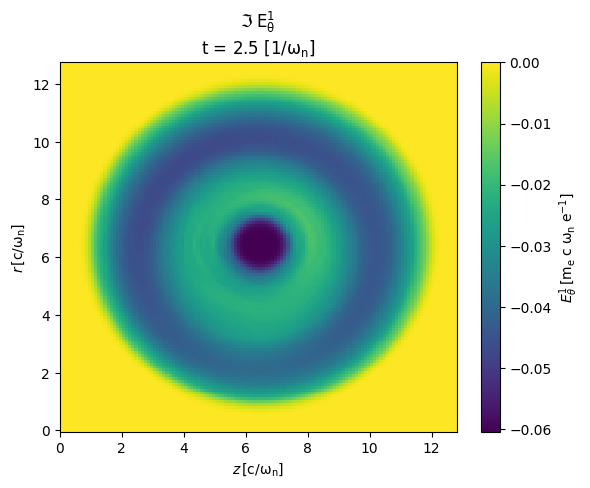

In [ ]:
def fname( comp, iter ):
    return "EMF/{:s}-{:06d}.zdf".format( comp, iter )

iter = 50

vis.plot_data(fname("E1z", iter), part = 'real' )
vis.plot_data(fname("E1z", iter), part = 'imag' )

vis.plot_data(fname("E1r", iter), part = 'real' )
vis.plot_data(fname("E1r", iter), part = 'imag' )

vis.plot_data(fname("E1θ", iter), part = 'real' )
vis.plot_data(fname("E1θ", iter), part = 'imag' )

### Beam test

In [75]:
! make -j 12 && mpirun -np 4 ./zpic

[c++]  main.cpp
[link] zpic
dt     = 0.0322394
ntiles = (8, 8)
quasi-3D tests
SIMD support not enabled
OpenMP enabled
dt     = 0.0322394
ntiles = (8, 8)
dt     = 0.0322394
ntiles = (8, 8)
  # procs           : 14
  max_threads       : 14
  default # threads : 14
Running test_beam()...
dt     = 0.0322394
ntiles = (8, 8)
Completed test_beam()


Plotting CHARGE/electrons/electrons-ρ0-001000.zdf


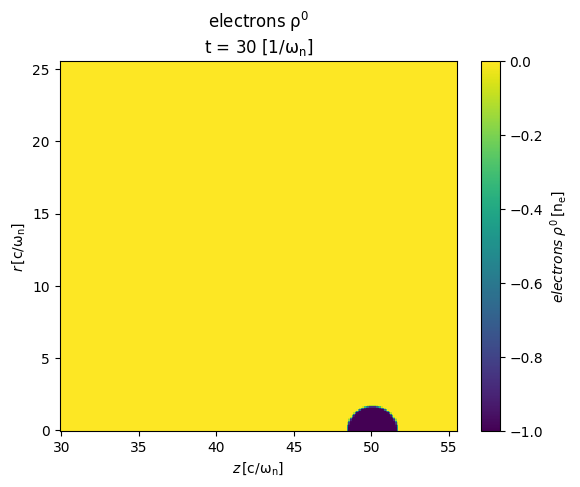

Plotting EMF/E0z-001000.zdf


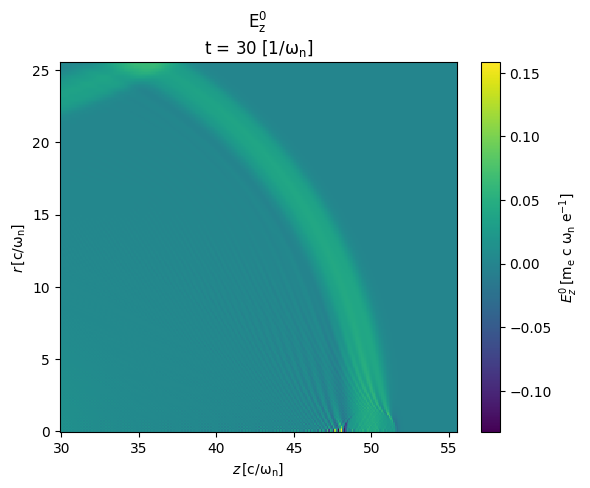

Plotting EMF/E0r-001000.zdf


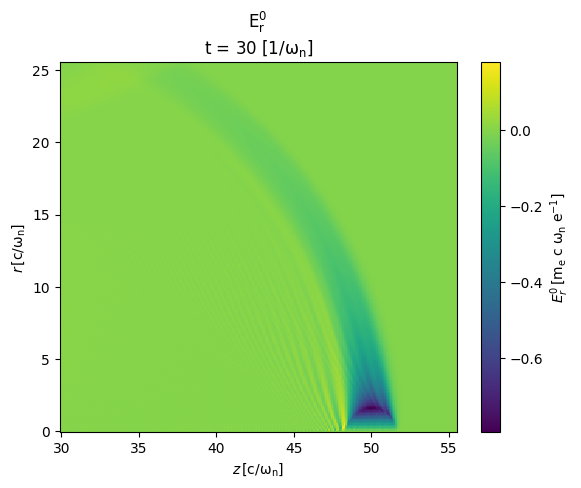

Plotting EMF/E0θ-001000.zdf


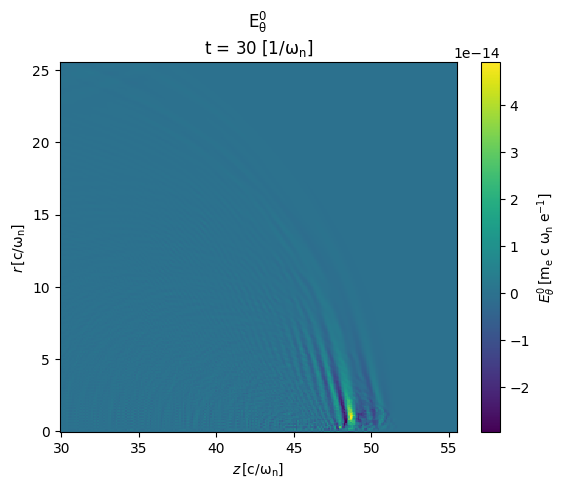

Plotting EMF/B0z-001000.zdf


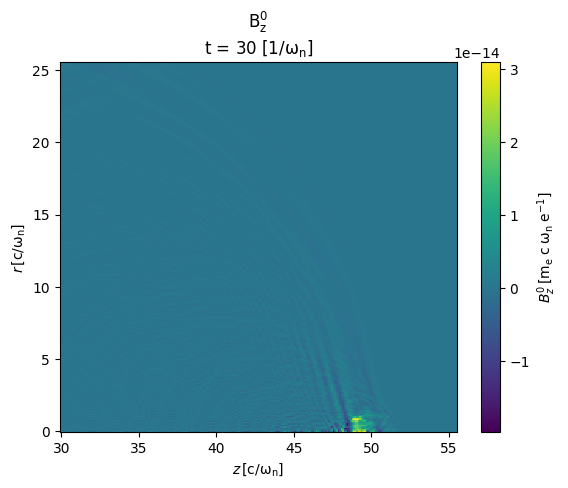

Plotting EMF/B0r-001000.zdf


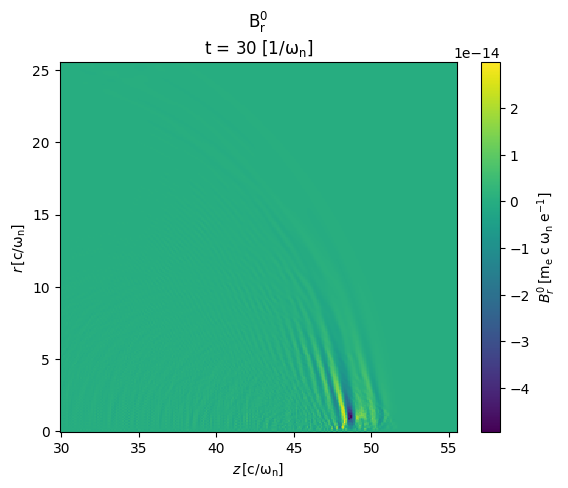

Plotting EMF/B0θ-001000.zdf


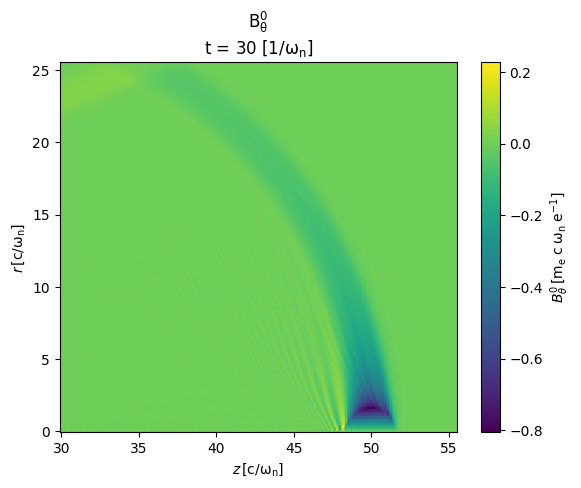

In [ ]:
import visxd as vis

iter = 1000

vis.plot_data("CHARGE/electrons/electrons-ρ0", iter )

vis.plot_data("EMF/E0z", iter )
vis.plot_data("EMF/E0r", iter )
vis.plot_data("EMF/E0θ", iter )

vis.plot_data("EMF/B0z", iter )
vis.plot_data("EMF/B0r", iter )
vis.plot_data("EMF/B0θ", iter )

### PWFA test

In [49]:
! make -j 12 && mpirun -np 4 ./zpic

[c++]  main.cpp
[link]  zpic
Environment
MPI running on 4 processes
GPU devices on rank 0 (GPUA100):
Device Number           : 0 (of 1)
  Device name           : NVIDIA A100 80GB PCIe
  Max. block size       : 1024
  Warp size             : 32
  Max. warps/block      : 32
  Shared memory (def.)  : 48 (kB) 
  Shared memory (optin) : 163 (kB) 
Running test_pwfa()...
dt     = 0.0344924
ntiles = (8, 8)
dt     = 0.0344924
ntiles = (8, 8)
dt     = 0.0344924
ntiles = (8, 8)
dt     = 0.0344924
ntiles = (8, 8)
Completed test_pwfa()


Plotting CHARGE/beam/beam-ρ0-001030.zdf


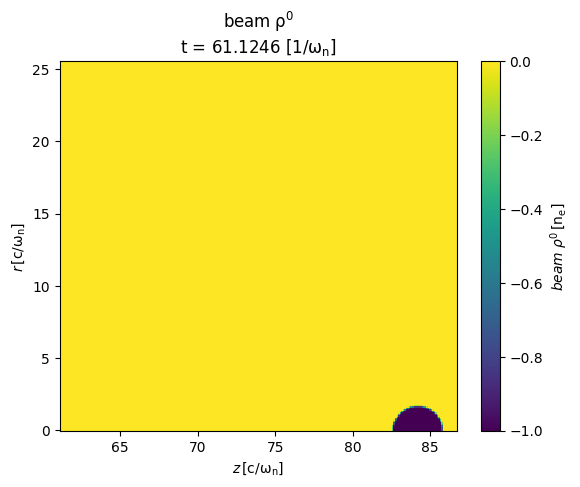

Plotting CHARGE/plasma/plasma-ρ0-001030.zdf


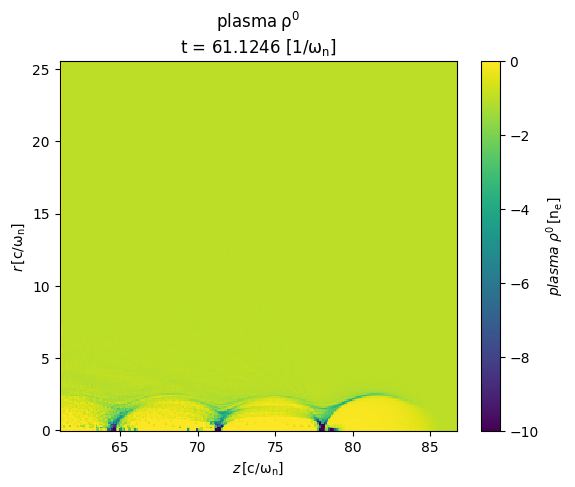

Plotting PARTICLES/plasma/particles-plasma-001030.zdf


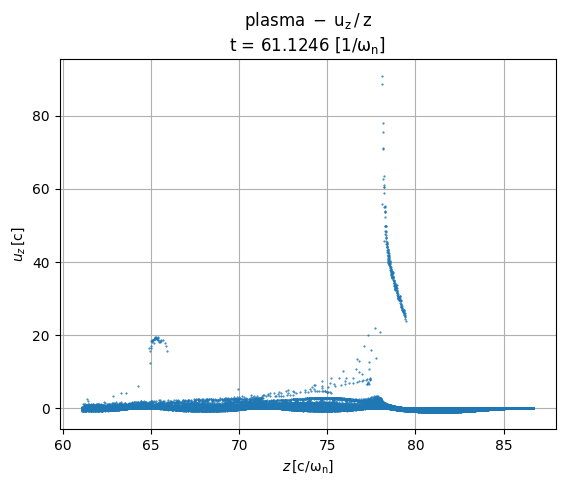

In [ ]:
import visxd as vis

iter = 1030

vis.plot_data("CHARGE/beam/beam-ρ0", iter )
vis.plot_data("CHARGE/plasma/plasma-ρ0", iter, vmin = -10 )

vis.plot_data("PARTICLES/plasma/particles-plasma", iter, qx = 'z', qy = 'uz' )

# vis.plot_data("CURRENT/J0z", iter )


# vis.plot_data("EMF/E0z", iter )
# vis.plot_data("EMF/E0r", iter )
# vis.plot_data("EMF/E0θ", iter )


# vis.plot_data("EMF/B0z", iter )
# vis.plot_data("EMF/B0r", iter )
# vis.plot_data("EMF/B0θ", iter )


#vis.plot_data("CURRENT/J0r", iter )
#vis.plot_data("CURRENT/J0θ", iter )

### LWFA test

In [30]:
! make -j 12 && mpirun -np 4 ./zpic

make: Nothing to be done for 'all'.
Environment
MPI running on 4 processes
GPU devices on rank 0 (GPUA100):
Device Number           : 0 (of 1)
  Device name           : NVIDIA A100 80GB PCIe
  Max. block size       : 1024
  Warp size             : 32
  Max. warps/block      : 32
  Shared memory (def.)  : 48 (kB) 
  Shared memory (optin) : 163 (kB) 
Running test_lwfa()...
Starting simulation, dt = 0.0175145
i = 0
i = 100
i = 200
i = 300
i = 400
i = 500
i = 600
i = 700
i = 800
i = 900
i = 1000
i = 1100
i = 1200
Simulation run up to t = 21.5078 in 74.6124 s
Done!


Plotting EMF/E0z-001200.zdf


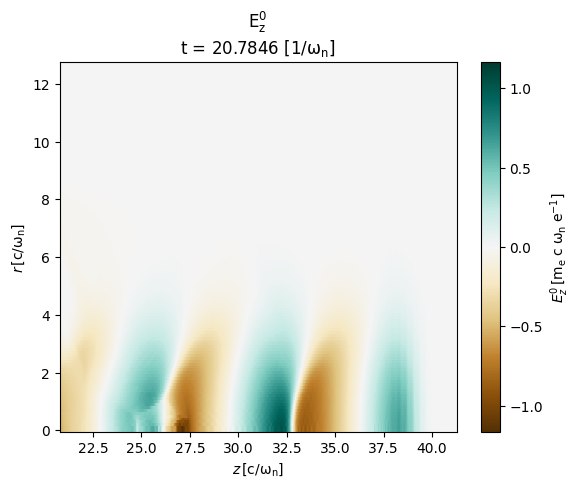

Plotting EMF/E0r-001200.zdf


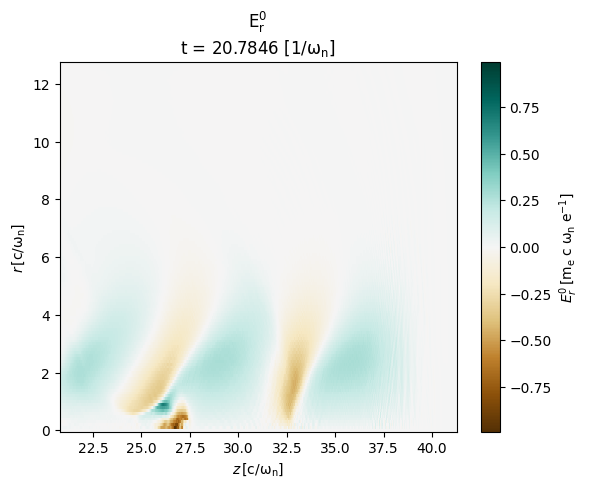

Plotting EMF/E0θ-001200.zdf


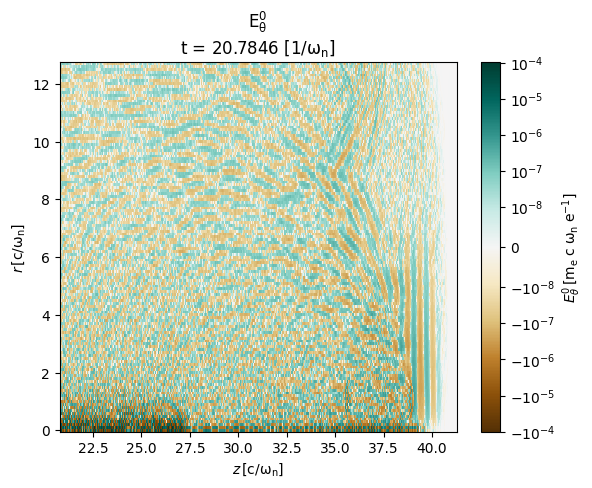

Plotting CHARGE/electrons/electrons-ρ0-001200.zdf


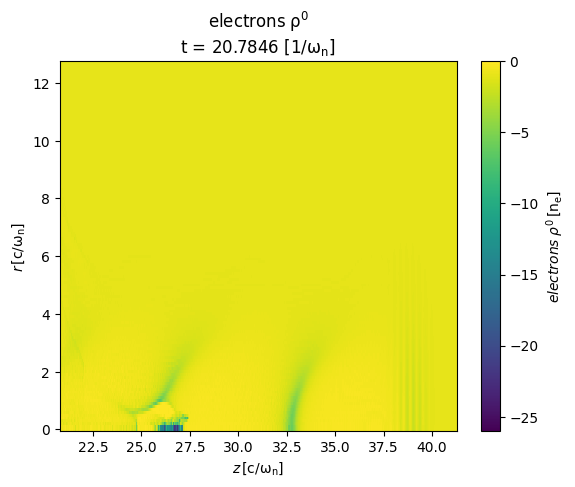

In [ ]:
import visxd as vis
from matplotlib.colors import SymLogNorm

# iter = 500
iter = 1200

vis.plot_data("EMF/E0z", iter, vsim = True, cmap = "BrBG" )
vis.plot_data("EMF/E0r", iter, vsim = True, cmap = "BrBG" )
vis.plot_data("EMF/E0θ", iter, norm = SymLogNorm( linthresh = 1.e-8), cmap = "BrBG" )

vis.plot_data("CHARGE/electrons/electrons-ρ0", iter )

#vis.plot_data("CURRENT/J0z", iter , vsim = True, cmap = "BrBG" )
#vis.plot_data("CURRENT/J0r", iter , vsim = True, cmap = "BrBG" )
#vis.plot_data("CURRENT/J0θ", iter , vsim = True, cmap = "BrBG" )

Plotting EMF/E1z-001200.zdf


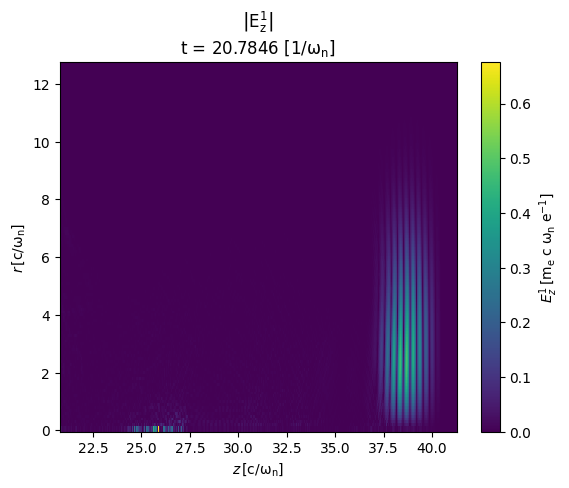

Plotting EMF/E1r-001200.zdf


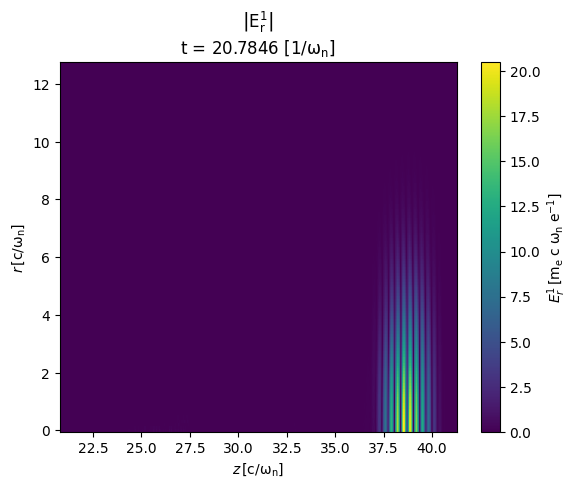

Plotting EMF/E1θ-001200.zdf


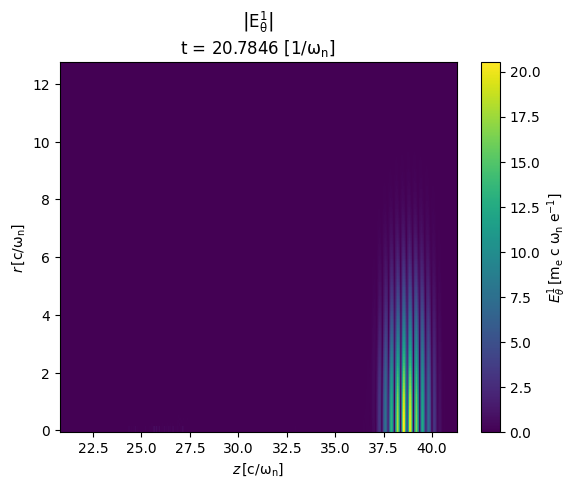

Plotting CHARGE/electrons/electrons-ρ1-001200.zdf


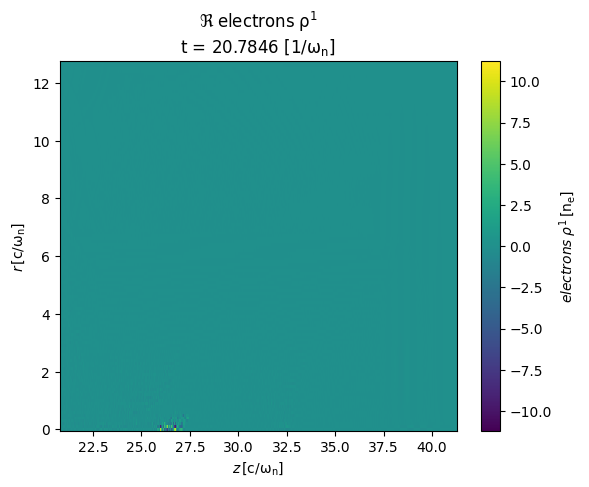

Plotting CURRENT/J1z-001200.zdf


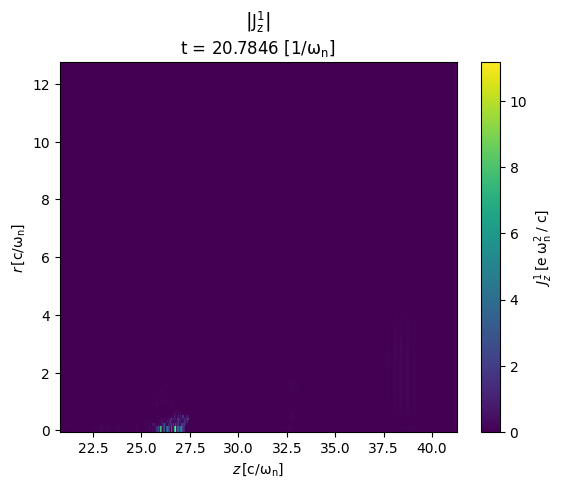

Plotting CURRENT/J1r-001200.zdf


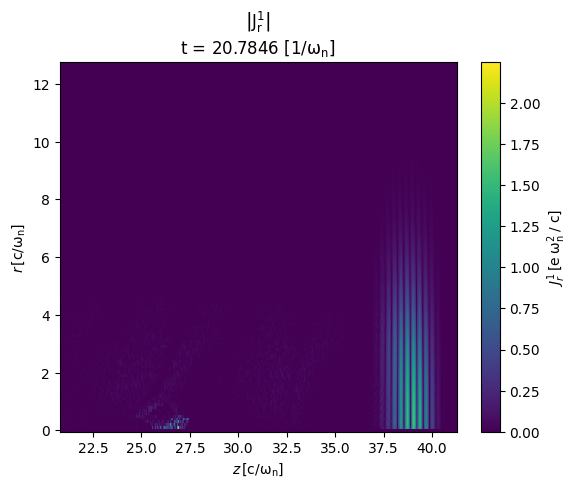

Plotting CURRENT/J1θ-001200.zdf


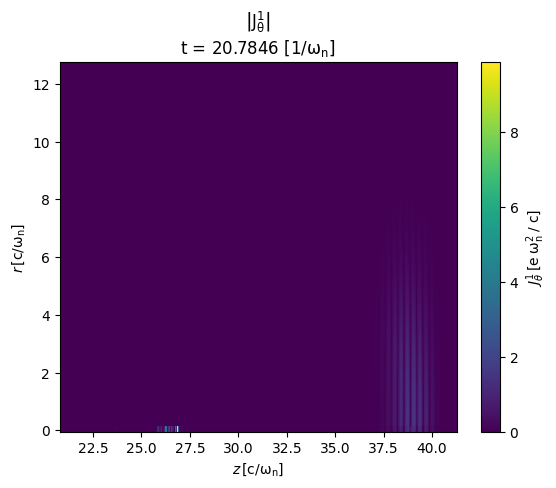

In [ ]:
import visxd.cyl as vis

def fname( folder, comp, iter ):
    return "{:s}/{:s}-{:06d}.zdf".format( folder, comp, iter )


# ! ls EMF

iter = 1200
# iter = 0

vis.plot_data(fname("EMF", "E1z", iter), part = 'abs' )
vis.plot_data(fname("EMF", "E1r", iter), part = 'abs' )
vis.plot_data(fname("EMF", "E1θ", iter), part = 'abs' )

vis.plot_data(fname("CHARGE/electrons", "electrons-ρ1", iter), part = 'real' )

vis.plot_data(fname("CURRENT", "J1z", iter), part = 'abs' )
vis.plot_data(fname("CURRENT", "J1r", iter), part = 'abs' )
vis.plot_data(fname("CURRENT", "J1θ", iter), part = 'abs' )